In [1]:
#Step 1:  Importing Required Libraries
import numpy as np 
import pandas as pd
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import confusion_matrix
import matplotlib.pyplot as plt
import seaborn as sns

In [4]:
# Step 2: Creating Sample Dataset
data = {
    'Height' : [170, 165, 180, 175, 168, 177, 162, 158],
    'Weight' : [65, 59, 75, 68, 55, 70, 62, 74],
    'Age' : [30, 25, 35, 28, 22, 32, 27, 33,],
    'Gender' : [1, 0, 1, 1, 0, 1, 0, 1] # 1 = Male, 0 = Female

}
df = pd.DataFrame(data)
print(df)

   Height  Weight  Age  Gender
0     170      65   30       1
1     165      59   25       0
2     180      75   35       1
3     175      68   28       1
4     168      55   22       0
5     177      70   32       1
6     162      62   27       0
7     158      74   33       1


In [6]:
# Standardizing the Data
X = df.drop('Gender', axis = 1)
y = df['Gender']
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

In [7]:
#Applying PCA Algorithm
pca = PCA(n_components = 2)
X_pca = pca.fit_transform(X_scaled)
X_train, X_test, y_train, y_test = train_test_split(X_pca, y, test_size = 0.3, random_state = 42)
model = LogisticRegression()
model.fit(X_train, y_train)
y_pred = model.predict(X_test)

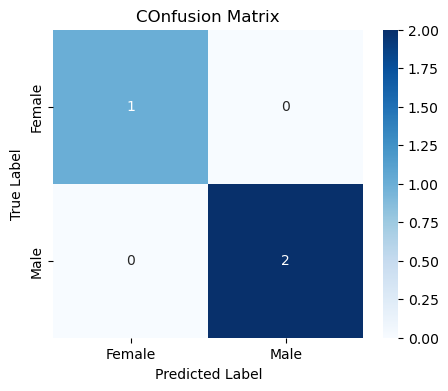

In [8]:
# Evaluting with Confusion Matrix
cm = confusion_matrix(y_test, y_pred)
plt.figure(figsize=(5,4))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', xticklabels=['Female','Male'], yticklabels = ['Female', 'Male'])
plt.xlabel('Predicted Label')
plt.ylabel('True Label')
plt.title('COnfusion Matrix')
plt.show()

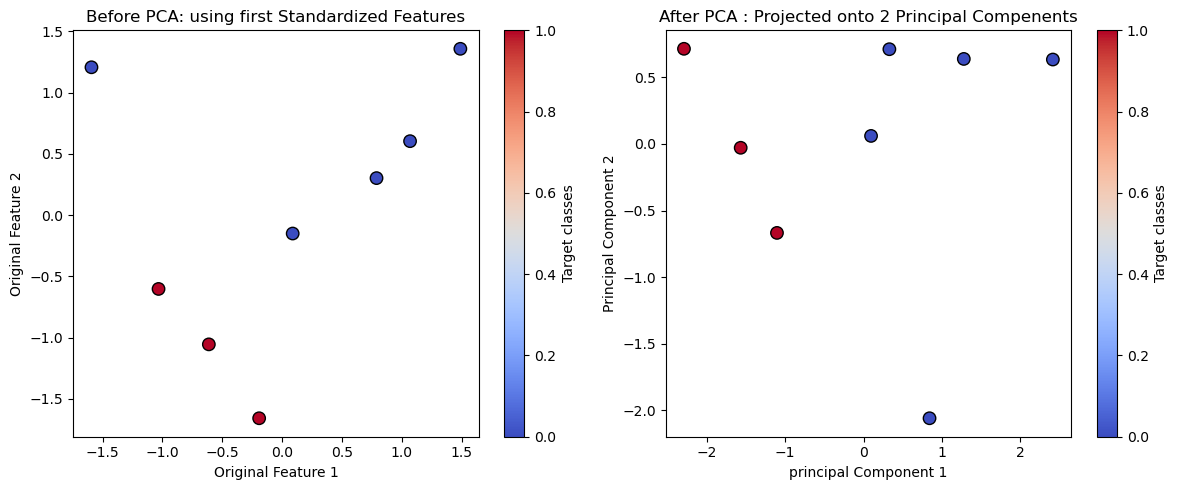

In [10]:
# Step 6: Visualizing PCA Result
y_numeric = pd.factorize(y)[0]
plt.figure(figsize = (12,5))
plt.subplot(1,2,1)
plt.scatter(X_scaled[:,0], X_scaled[:,1], c=y_numeric,cmap ='coolwarm', edgecolor='k', s=80)
plt.xlabel('Original Feature 1')
plt.ylabel('Original Feature 2')
plt.title('Before PCA: using first Standardized Features')
plt.colorbar(label='Target classes')

plt.subplot(1,2,2)
plt.scatter(X_pca[:,0], X_pca[:, 1], c=y_numeric, cmap='coolwarm', edgecolor='k',s=80)
plt.xlabel('principal Component 1')
plt.ylabel('Principal Component 2')
plt.title('After PCA : Projected onto 2 Principal Compenents')
plt.colorbar(label='Target classes')
plt.tight_layout()
plt.show()